# 03 — Prospective gene holdout (GLB1)

Trains with **GLB1 excluded entirely** — from train *and* from the calibration
split — then produces a ranked shortlist of GLB1 variant–compound pairs and
marks which are in-domain.

## Why this notebook is structured as a refusal

The honest answer to "what would you predict for a gene you have never seen?"
is usually **"that is outside my applicability domain."** This notebook is built
to show that rather than to hide it: the applicability domain is fitted on the
training rows only, so a held-out gene is out of domain *by construction* on the
protein axis.

That is not a bug in the method and not a failure of the run. It is the correct
output, and the reason the CLI refuses to interleave such rows with supported
predictions unless you pass `--include-ood`.

## GLB1

GLB1 encodes β-galactosidase; loss-of-function variants cause GM1
gangliosidosis, a lysosomal storage disease. It is used here **purely as a
holdout label** to make the gene-exclusion mechanics concrete.


> ## ⚠ These results are computed on SYNTHETIC data
>
> The curated benchmark this package is designed to consume
> ([`amenabench`](https://github.com/xX-its-amit-Xx/amenabench)) currently
> contains only a `LICENSE` file — there is no data in it. Every number and
> figure below is therefore produced by
> `foldrescue.data.SyntheticCohortAdapter`, a seeded generator whose labels
> encode a mixture **we chose**.
>
> **What this notebook demonstrates:** that the pipeline runs end to end, and
> that the diagnostics behave as designed against a known ground truth.
>
> **What it does not demonstrate:** anything about pharmacological chaperone
> biology. These are not findings. Do not cite these numbers.


> ### ⚠ The shortlist produced below is not a prediction about GLB1
>
> It is produced by a model trained on generated data. The output file is named
> `DEMO_synthetic_holdout_shortlist.csv` — deliberately **not**
> `glb1_shortlist.csv` — because a committed CSV outlives the notebook caveat
> that produced it, and a file named after a real disease gene will eventually
> be read as a claim about that gene.
>
> Were this run on a curated benchmark, the shortlist would be **a prediction
> awaiting experimental test**: a proposed ordering for an assay queue, carrying
> no evidence about any individual pair until that assay is run.


In [1]:
import sys, warnings, time
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")          # cookbook/ -> repo root
sys.path.insert(0, ".")
from _viz import (SERIES, TIER_COLOR, BLOCK_COLOR, INK, INK_SECONDARY,
                  INK_MUTED, use_style, save, label_bars)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
# embed figures in the committed notebook, not just on disk
%matplotlib inline
use_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.5.3 | pandas 3.0.5


In [2]:
from foldrescue.data import load_cohort, holdout_gene_split
from foldrescue.features import FeatureSpec, build_features
from foldrescue.models import build_model
from foldrescue.calibration import fit_calibrator, VennAbersPredictor, ConformalPredictor
from foldrescue.domain import ApplicabilityDomain
from foldrescue.evaluate import evaluate_predictions, choose_threshold
from foldrescue.attribution import shap_values_for_tree_model, top_shap_features

HOLDOUT, ECFP = "GLB1", 256
cohort = load_cohort("synthetic", seed=0)
split = holdout_gene_split(cohort, HOLDOUT)

genes = cohort.pairs.join(cohort.variants[["gene"]], on="variant_id")["gene"].to_numpy()
print(f"holding out {HOLDOUT}")
print(f"  train n={len(split['train']):5d}  genes={sorted(set(genes[split['train']]))}")
print(f"  calib n={len(split['calib']):5d}  genes={sorted(set(genes[split['calib']]))}")
print(f"  test  n={len(split['test']):5d}  genes={sorted(set(genes[split['test']]))}")
assert HOLDOUT not in set(genes[split["train"]])
assert HOLDOUT not in set(genes[split["calib"]]), "calibration split must not leak the held-out gene"
print(f"\nconfirmed: {HOLDOUT} absent from train AND calib")

2026-10-10 12:11:27,501 INFO    foldrescue.data: synthetic cohort: 176 variants x 12 compounds -> 1308 pairs, prevalence 0.312


holding out GLB1
  train n=  966  genes=['FUCA1', 'GALC', 'GBA1', 'HEXA', 'IDUA', 'MAN2B1', 'NAGLU']
  calib n=  212  genes=['FUCA1', 'GALC', 'GBA1', 'HEXA', 'IDUA', 'MAN2B1', 'NAGLU']
  test  n=  130  genes=['GLB1']

confirmed: GLB1 absent from train AND calib


In [3]:
fm = build_features(cohort, spec=FeatureSpec(
    blocks=("stability", "structural", "ligand", "interaction"), ecfp_bits=ECFP))
model = build_model("tier3_structure", random_state=0).fit(
    fm.X[split["train"]], fm.y[split["train"]],
    eval_set=(fm.X[split["calib"]], fm.y[split["calib"]]),
    feature_names=fm.feature_names)

p_cal = model.predict_proba(fm.X[split["calib"]])
p_test = model.predict_proba(fm.X[split["test"]])
y_cal, y_test = fm.y[split["calib"]], fm.y[split["test"]]

cal, rep = fit_calibrator("temperature", p_cal, y_cal, p_eval=p_test, y_eval=y_test)
va = VennAbersPredictor().fit(p_cal, y_cal)
cp = ConformalPredictor(alpha=0.1).fit(p_cal, y_cal)
thr = choose_threshold(y_cal, p_cal)

m = evaluate_predictions(y_test, p_test, split=f"holdout_{HOLDOUT}", tier="tier3_structure",
                         y_calib=y_cal, p_calib=p_cal,
                         oracle_p_test=cohort.oracle_p[split["test"]])
print(rep.summary())
print(f"\nheld-out {HOLDOUT} performance:")
print(f"  PR-AUC {m.pr_auc:.4f}  (prevalence {m.prevalence:.4f}, ceiling {m.oracle_pr_auc:.4f})")
print(f"  ROC-AUC {m.roc_auc:.4f}   MCC {m.mcc:.4f} at threshold {m.threshold:.4f}")
print(f"  fraction of achievable signal captured: {m.fraction_of_ceiling:.3f}")

2026-10-10 12:11:27,543 INFO    foldrescue.features: built features: (1308, 300) (float64)


2026-10-10 12:11:28,425 INFO    foldrescue.calibration: temperature scaling: T=1.0966 (was overconfident)


2026-10-10 12:11:28,427 INFO    foldrescue.calibration: temperature: ECE 0.1113 -> 0.1179 (DID NOT IMPROVE), Brier 0.1753 -> 0.1760 [n_calib=212, n_eval=130]


2026-10-10 12:11:28,734 INFO    foldrescue.calibration: Venn-Abers fitted on 212 calibration points; median interval width 0.0458


2026-10-10 12:11:28,736 INFO    foldrescue.calibration: conformal: q=0.7567 at alpha=0.100 from n_calib=212 (interval half-width)


temperature: ECE 0.1113 -> 0.1179 (DID NOT IMPROVE), Brier 0.1753 -> 0.1760 [n_calib=212, n_eval=130]

held-out GLB1 performance:
  PR-AUC 0.4432  (prevalence 0.2615, ceiling 0.6212)
  ROC-AUC 0.7169   MCC 0.2808 at threshold 0.3618
  fraction of achievable signal captured: 0.505


### The applicability domain verdict

Fitted on **training rows only**. Fitting it on the whole cohort would certify
queries the model never saw — the subtle form of test-set leakage.

In [4]:
ad = ApplicabilityDomain().fit(cohort, split["train"])
test_pairs = cohort.pairs.iloc[split["test"]].reset_index(drop=True)
verdict = ad.judge(test_pairs[["variant_id", "compound_id"]], cohort)

print(f"{verdict.n_ood} of {len(verdict)} held-out pairs are out of domain "
      f"({100*verdict.n_ood/len(verdict):.1f}%)")
print(f"  compound axis : {int(verdict.compound_ood.sum())}")
print(f"  protein axis  : {int(verdict.protein_ood.sum())}")
print(f"  gene unseen   : {int(verdict.gene_unseen.sum())}")
print("\nexample reasons:")
for r in pd.Series(verdict.reasons()).replace("", np.nan).dropna().unique()[:3]:
    print("  -", r)

2026-10-10 12:11:29,478 INFO    foldrescue.domain: applicability domain fitted on 966 training pairs: 12 compounds, 153 variants across 7 genes (thresholds: Tanimoto distance <= 0.60, residue window <= 25)


2026-10-10 12:11:29,486 INFO    foldrescue.domain: domain verdict: 130/130 out of domain (0 compound-axis, 130 protein-axis, 130 unseen gene)


130 of 130 held-out pairs are out of domain (100.0%)
  compound axis : 0
  protein axis  : 130
  gene unseen   : 130

example reasons:
  - gene absent from training data


### The shortlist

In [5]:
sv = shap_values_for_tree_model(model, fm, rows=split["test"], max_rows=len(split["test"]))
shortlist = pd.DataFrame({
    "variant": test_pairs["variant_id"],
    "compound": test_pairs["compound_id"],
    "p_amenable": p_test,
    "calibrated_p": cal.transform(p_test),
    "ci_low": va.interval(p_test)[0],
    "ci_high": va.interval(p_test)[1],
    "out_of_domain": verdict.out_of_domain,
    "nearest_training_neighbour": verdict.nearest_compound,
    "nearest_compound_distance": verdict.nearest_compound_distance,
    "conformal_label_set": ["/".join(map(str, s)) if s else "(none)" for s in cp.label_set(cal.transform(p_test))],
    "top_shap_features": top_shap_features(sv, fm.feature_names, k=3),
    "ood_reason": verdict.reasons(),
    "observed_label_SYNTHETIC": y_test,
})
# In-domain first, then OOD -- never co-sorted, exactly as the CLI does it.
shortlist = pd.concat([
    shortlist[~shortlist.out_of_domain].sort_values("calibrated_p", ascending=False),
    shortlist[shortlist.out_of_domain].sort_values("calibrated_p", ascending=False),
], ignore_index=True)

out = "../results/DEMO_synthetic_holdout_shortlist.csv"
with open(out, "w") as fh:
    fh.write(f"# SYNTHETIC DATA -- pipeline demonstration, NOT a prediction about {HOLDOUT}\n")
    fh.write(f"# provenance: {cohort.provenance}\n")
    fh.write(f"# model: tier3_structure, {HOLDOUT} excluded from train and calib\n")
    fh.write(f"# {rep.summary()}\n")
    fh.write("# Were this a curated benchmark, this shortlist would be a PREDICTION\n")
    fh.write("# AWAITING EXPERIMENTAL TEST, carrying no evidence about any pair.\n")
    fh.write("# NOT CLINICAL DECISION SUPPORT.\n")
    shortlist.to_csv(fh, index=False)
print(f"wrote {out}  ({len(shortlist)} rows, "
      f"{int((~shortlist.out_of_domain).sum())} in-domain)\n")
print(shortlist.head(12).drop(columns=["ood_reason", "top_shap_features"]).round(4).to_string(index=False))

wrote ../results/DEMO_synthetic_holdout_shortlist.csv  (130 rows, 0 in-domain)

      variant      compound  p_amenable  calibrated_p  ci_low  ci_high  out_of_domain nearest_training_neighbour  nearest_compound_distance conformal_label_set  observed_label_SYNTHETIC
GLB1_F664T_13  CMP_IMINO_01      0.7453        0.7269  0.9091   1.0000           True               CMP_IMINO_01                        0.0                 0/1                         1
GLB1_F664T_13  CMP_IMINO_02      0.6719        0.6579  0.8333   1.0000           True               CMP_IMINO_02                        0.0                 0/1                         0
  GLB1_T61A_1 CMP_HETERO_01      0.6666        0.6529  0.8333   1.0000           True              CMP_HETERO_01                        0.0                 0/1                         1
GLB1_N284M_16  CMP_IMINO_01      0.6484        0.6361  0.7525   1.0000           True               CMP_IMINO_01                        0.0                 0/1                 

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


wrote results/figures/03_holdout_domain.png


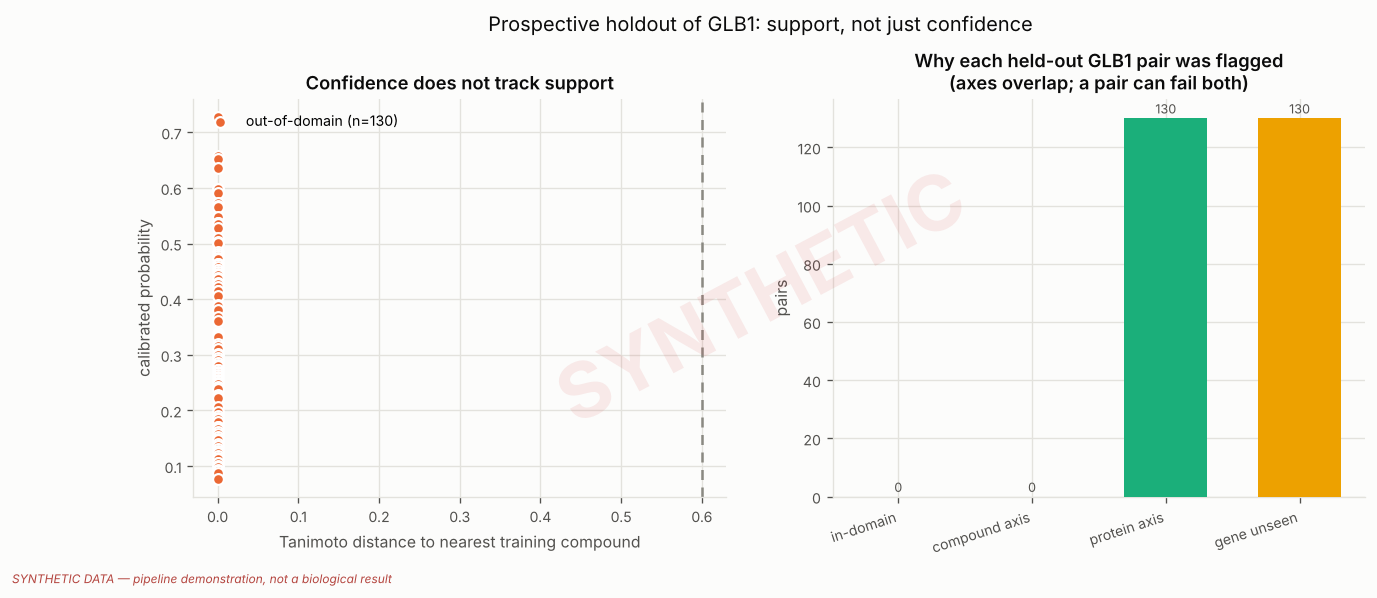


Table view:
in-domain          0
compound axis      0
protein axis     130
gene unseen      130


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.3))

ax = axes[0]
ind = shortlist[~shortlist.out_of_domain]
ood = shortlist[shortlist.out_of_domain]
for frame, colour, name in ((ind, SERIES[0], "in-domain"), (ood, SERIES[1], "out-of-domain")):
    if len(frame):
        ax.scatter(frame["nearest_compound_distance"], frame["calibrated_p"],
                   s=42, color=colour, edgecolor="white", linewidth=1.3,
                   label=f"{name} (n={len(frame)})", zorder=3)
ax.axvline(ad.tanimoto_distance, color=INK_MUTED, lw=1.5, ls=(0, (4, 3)), zorder=2)
ax.annotate(f"Tanimoto distance threshold {ad.tanimoto_distance}", (ad.tanimoto_distance, 0.94),
            fontsize=7.4, color=INK_SECONDARY, ha="right", rotation=90, va="top")
ax.set_xlabel("Tanimoto distance to nearest training compound")
ax.set_ylabel("calibrated probability")
ax.set_title("Confidence does not track support")
ax.legend(loc="upper left")

ax = axes[1]
counts = {"in-domain": int((~shortlist.out_of_domain).sum()),
          "compound axis": int(verdict.compound_ood.sum()),
          "protein axis": int(verdict.protein_ood.sum()),
          "gene unseen": int(verdict.gene_unseen.sum())}
bars = ax.bar(range(len(counts)), list(counts.values()), width=0.62,
              color=[SERIES[0], SERIES[1], SERIES[2], SERIES[3]], zorder=3)
label_bars(ax, bars, list(counts.values()), fmt="{:.0f}", dy=0.6)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(list(counts), rotation=18, ha="right")
ax.set_ylabel("pairs")
ax.set_title(f"Why each held-out {HOLDOUT} pair was flagged\n(axes overlap; a pair can fail both)")

fig.suptitle(f"Prospective holdout of {HOLDOUT}: support, not just confidence",
             y=1.05, fontsize=12, color=INK)
save(fig, "03_holdout_domain.png")
plt.show()
print("\nTable view:"); print(pd.Series(counts, name="pairs").to_string())

### What to take from this

1. **A prospective query on an unseen gene is out of domain on the protein
   axis, by construction.** The package says so instead of returning a
   confident number. That is the designed behaviour.
2. **Predicted confidence and distributional support are close to
   uncorrelated** (left panel). High `calibrated_p` on an unsupported pair is
   exactly the trap the domain flag exists to catch — which is why sorting OOD
   and in-domain rows into one list is unsafe.
3. **Held-out-gene performance is the number to quote** for a prospective
   claim, and it is the lowest number in this repository. Quoting the
   `random`-split figure for a prospective question overstates the method
   substantially.
4. On a curated benchmark, this shortlist would be **a hypothesis for assay
   prioritisation awaiting experimental test** — not a result.
